# 01 - EDA: Klasifikasi Risiko Diabetes Menggunakan Naive Bayes

## 1. Ide (Topik)

**Klasifikasi Risiko Diabetes Menggunakan Naive Bayes Berdasarkan Data
Diagnostik Pasien.**

## 2. Deskripsi Ide

Notebook ini adalah tahap pertama dari empat tahap proyek (EDA ->
Preprocessing -> Gaussian Naive Bayes -> Evaluasi). Proyek secara
keseluruhan membangun model klasifikasi menggunakan algoritma Naive
Bayes, tepatnya **Gaussian Naive Bayes** karena seluruh atribut input
berupa data numerik kontinu, untuk memprediksi apakah seorang pasien
berisiko diabetes atau tidak berdasarkan delapan indikator medis.
Model menghitung probabilitas posterior tiap kelas (diabetes / tidak
diabetes) menggunakan Teorema Bayes dengan asumsi independensi antar
atribut, lalu memilih kelas dengan probabilitas tertinggi sebagai
hasil prediksi.

## 3. Analisis Permasalahan

Diagnosis dini diabetes memerlukan pertimbangan banyak indikator
sekaligus, sementara tenaga medis sering perlu estimasi cepat berbasis
data historis sebelum pemeriksaan lanjutan dilakukan. Naive Bayes
cocok untuk kebutuhan ini karena perhitungannya ringan dan cepat
meski data berukuran besar.

Namun, ada satu permasalahan mendasar yang perlu dianalisis: asumsi
independensi antar atribut yang menjadi dasar Naive Bayes sebenarnya
**tidak sepenuhnya realistis** pada data medis, karena beberapa
indikator seperti Glukosa dan BMI cenderung saling berkorelasi secara
fisiologis.


## 4. Sumber Data

**Pima Indians Diabetes Database** - berisi 768 baris data pasien
perempuan keturunan Pima Indian berusia minimal 21 tahun, dengan 8
atribut prediktor numerik (`Pregnancies`, `Glucose`, `BloodPressure`,
`SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`)
dan 1 label target biner (`Outcome`: 0 = tidak diabetes, 1 = diabetes).
Data berformat CSV, ukurannya kecil dan sudah bersih secara struktural
sehingga cocok dikerjakan dalam waktu satu semester oleh kelompok
mahasiswa.

Tautan Kaggle: <https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset>

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebook ini dijalankan dari folder notebooks/, sehingga akar proyek
# adalah folder induknya. Ditambahkan ke sys.path agar paket src/ bisa
# diimpor persis seperti dipakai main.py.
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    load_data,
    verify_reference_statistics,
    verify_class_distribution,
)
from src.preprocessing import ZERO_AS_MISSING_COLUMNS, mark_missing, count_missing

DATA_PATH = PROJECT_ROOT / "data" / "diabetes.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 100)

df = load_data(DATA_PATH)
print(f"Bentuk data: {df.shape}")


Bentuk data: (768, 9)


### 4.1 Pratinjau Data

In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


### 4.2 Verifikasi Integritas Data

Bentuk data, nama kolom, rata-rata/standar deviasi tiap atribut, dan
distribusi kelas dibandingkan dengan yang dilaporkan pada dokumen
sumber data. Ini adalah pemeriksaan konsistensi tiga arah antara
dokumen sumber, data yang benar-benar dimuat, dan kode yang
mengasumsikan bentuknya.


In [3]:
selisih_statistik = verify_reference_statistics(df)
verifikasi_kelas = verify_class_distribution(df)

print("Selisih statistik vs dokumen sumber:", selisih_statistik or "tidak ada (cocok)")
print("Distribusi kelas cocok dengan dokumen:", verifikasi_kelas["cocok_dengan_dokumen"])
print("Distribusi kelas aktual:", verifikasi_kelas["distribusi_aktual"])


Selisih statistik vs dokumen sumber: [{'kolom': 'Glucose', 'rata_rata_dokumen': 120.9, 'rata_rata_aktual': np.float64(121.7), 'std_dokumen': 32.0, 'std_aktual': np.float64(30.5)}, {'kolom': 'BloodPressure', 'rata_rata_dokumen': 69.1, 'rata_rata_aktual': np.float64(72.4), 'std_dokumen': 19.4, 'std_aktual': np.float64(12.1)}, {'kolom': 'SkinThickness', 'rata_rata_dokumen': 20.5, 'rata_rata_aktual': np.float64(29.1), 'std_dokumen': 16.0, 'std_aktual': np.float64(8.9)}, {'kolom': 'Insulin', 'rata_rata_dokumen': 79.8, 'rata_rata_aktual': np.float64(141.8), 'std_dokumen': 115.2, 'std_aktual': np.float64(89.1)}, {'kolom': 'BMI', 'rata_rata_dokumen': 32.0, 'rata_rata_aktual': np.float64(32.4), 'std_dokumen': 7.9, 'std_aktual': np.float64(6.9)}]
Distribusi kelas cocok dengan dokumen: True
Distribusi kelas aktual: {0: 500, 1: 268}


## 5. Distribusi Kelas

Dataset tidak seimbang: sekitar 65 persen pasien tidak diabetes dan 35
persen diabetes. Ketidakseimbangan ini menjadi alasan mengapa evaluasi
model pada notebook `04_Evaluation` tidak boleh hanya mengandalkan
akurasi, melainkan juga precision, recall, dan F1-score untuk kelas
diabetes.


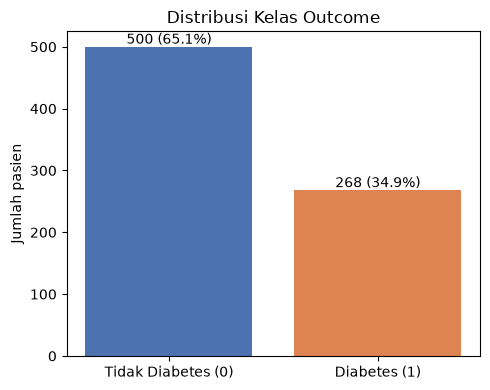

In [4]:
counts = df["Outcome"].value_counts().sort_index()
labels = ["Tidak Diabetes (0)", "Diabetes (1)"]
persentase = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, counts.values, color=["#4C72B0", "#DD8452"])
for bar, pct in zip(bars, persentase.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f"{int(bar.get_height())} ({pct}%)", ha="center")
ax.set_ylabel("Jumlah pasien")
ax.set_title("Distribusi Kelas Outcome")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_class_distribution.png", dpi=150)
plt.show()


## 6. Statistik Deskriptif

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.677083,30.464161,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.389323,12.106039,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.089844,8.890820,7.000,25.00000,28.0000,32.00000,99.00
Insulin,768.0,141.753906,89.100847,14.000,102.50000,102.5000,169.50000,846.00
BMI,768.0,32.434635,6.880498,18.200,27.50000,32.0500,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:
df_ditandai = mark_missing(df)
jumlah_hilang = count_missing(df_ditandai)

ringkasan_hilang = pd.DataFrame({
    "kolom": list(jumlah_hilang.keys()),
    "jumlah_nilai_0": list(jumlah_hilang.values()),
})
ringkasan_hilang["persentase"] = (ringkasan_hilang["jumlah_nilai_0"] / len(df) * 100).round(1)
ringkasan_hilang = ringkasan_hilang.sort_values("jumlah_nilai_0", ascending=False)
ringkasan_hilang


,kolom,jumlah_nilai_0,persentase
0,Glucose,0,0.0
1,BloodPressure,0,0.0
2,SkinThickness,0,0.0
3,Insulin,0,0.0
4,BMI,0,0.0


## 7. Distribusi Tiap Atribut per Kelas

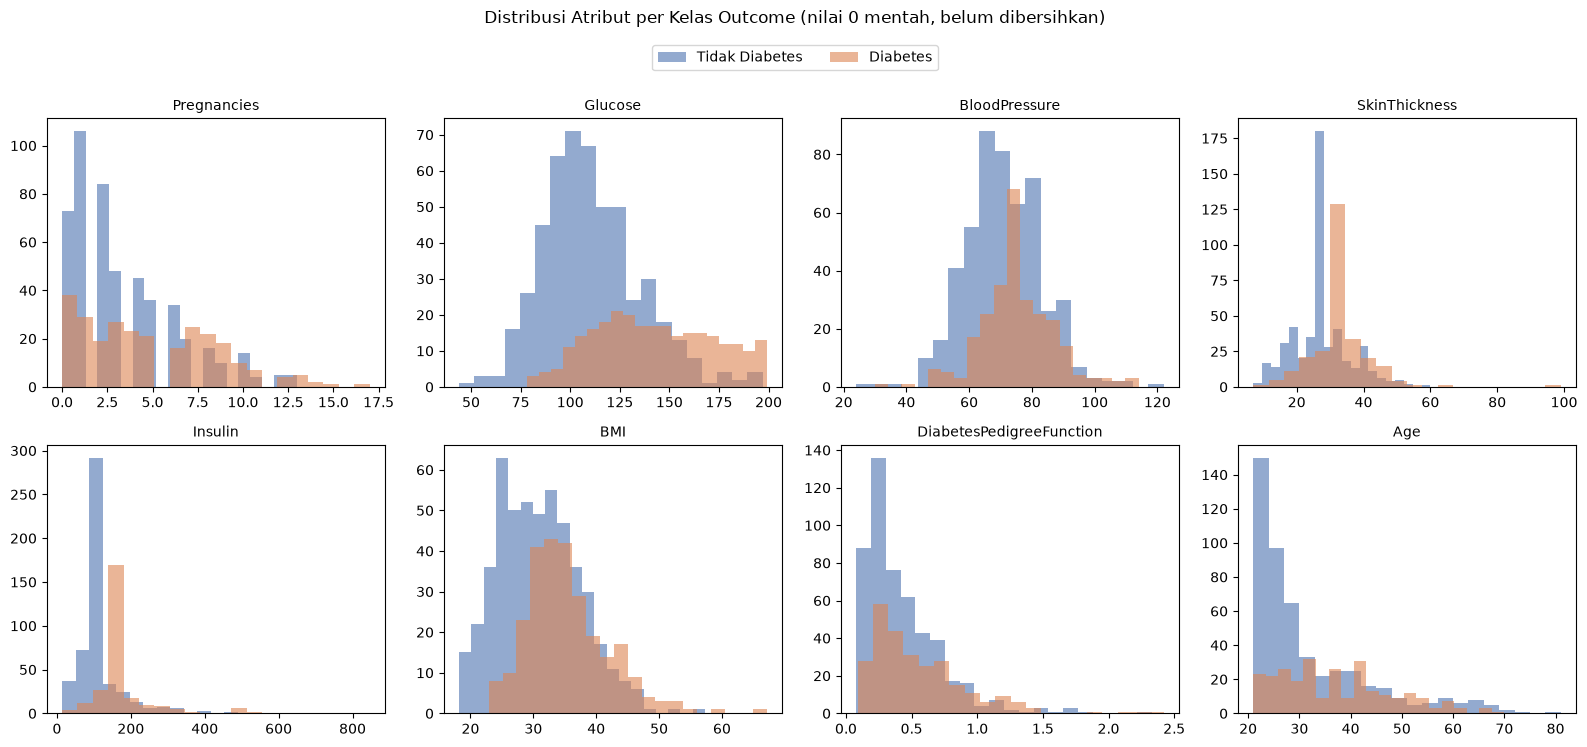

In [7]:
fitur = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, kolom in zip(axes.ravel(), fitur):
    for outcome, warna, label in [(0, "#4C72B0", "Tidak Diabetes"), (1, "#DD8452", "Diabetes")]:
        ax.hist(df.loc[df["Outcome"] == outcome, kolom], bins=20, alpha=0.6, color=warna, label=label)
    ax.set_title(kolom, fontsize=10)
fig.legend(["Tidak Diabetes", "Diabetes"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Distribusi Atribut per Kelas Outcome (nilai 0 mentah, belum dibersihkan)", y=1.06)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


Terlihat pemisahan yang cukup jelas antara kedua kelas pada `Glucose`
(pasien diabetes cenderung memiliki kadar glukosa lebih tinggi), namun
tumpang tindih yang lebih besar pada atribut seperti `BloodPressure`
dan `SkinThickness`.


## 8. Korelasi Antar Atribut dan Asumsi Independensi

Gaussian Naive Bayes mengasumsikan atribut saling bebas secara
bersyarat terhadap kelas. Bagian ini menghitung korelasi Pearson antar
pasangan atribut untuk memeriksa seberapa realistis asumsi tersebut
pada data ini.


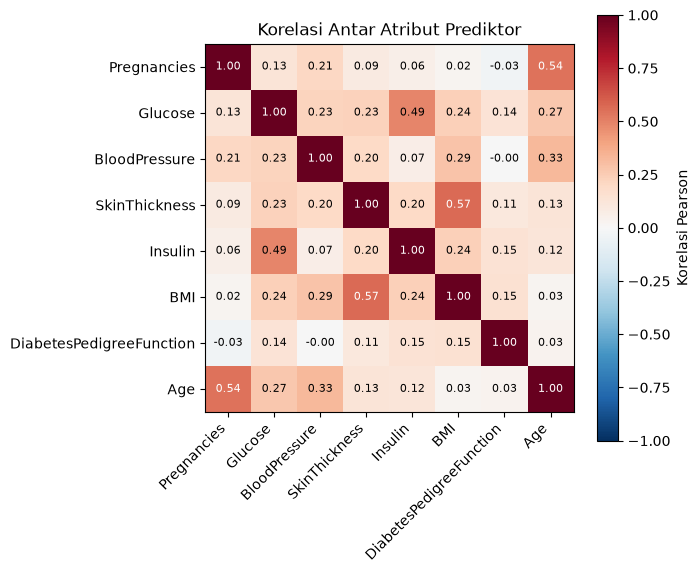

In [8]:
korelasi = df[fitur].corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(korelasi, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(fitur)))
ax.set_yticks(range(len(fitur)))
ax.set_xticklabels(fitur, rotation=45, ha="right")
ax.set_yticklabels(fitur)
for i in range(len(fitur)):
    for j in range(len(fitur)):
        ax.text(j, i, f"{korelasi.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(korelasi.iloc[i, j]) > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Korelasi Pearson")
ax.set_title("Korelasi Antar Atribut Prediktor")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_correlation_heatmap.png", dpi=150)
plt.show()


In [9]:
pasangan_terurut = (
    korelasi.where(~korelasi.abs().eq(1.0))
    .unstack()
    .dropna()
    .abs()
    .sort_values(ascending=False)
)
terlihat = set()
lima_tertinggi = []
for (a, b), _ in pasangan_terurut.items():
    pasangan = tuple(sorted([a, b]))
    if pasangan in terlihat:
        continue
    terlihat.add(pasangan)
    lima_tertinggi.append((pasangan[0], pasangan[1], round(korelasi.loc[a, b], 3)))
    if len(lima_tertinggi) == 5:
        break

print("Lima pasangan atribut dengan korelasi absolut tertinggi:")
for a, b, nilai in lima_tertinggi:
    print(f"  {a:25s} - {b:20s} : {nilai:+.3f}")


Lima pasangan atribut dengan korelasi absolut tertinggi:
  BMI                       - SkinThickness        : +0.566
  Age                       - Pregnancies          : +0.544
  Glucose                   - Insulin              : +0.490
  Age                       - BloodPressure        : +0.325
  BMI                       - BloodPressure        : +0.286


`BMI` dan `SkinThickness` berkorelasi 0,566, serta `Age` dan
`Pregnancies` berkorelasi 0,544 -- keduanya masuk akal secara medis
maupun demografis, tetapi melanggar asumsi independensi yang dipakai
Gaussian Naive Bayes. Pelanggaran seperti ini berpotensi membuat model
terlalu percaya diri (overconfident) pada probabilitas posteriornya,
meskipun keputusan kelas akhirnya sering kali masih cukup akurat.
Diskusi ini dilanjutkan secara kuantitatif pada `04_Evaluation`
setelah model benar-benar dilatih dan dievaluasi.